# 3.1 So sánh các mô hình phân loại
**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)

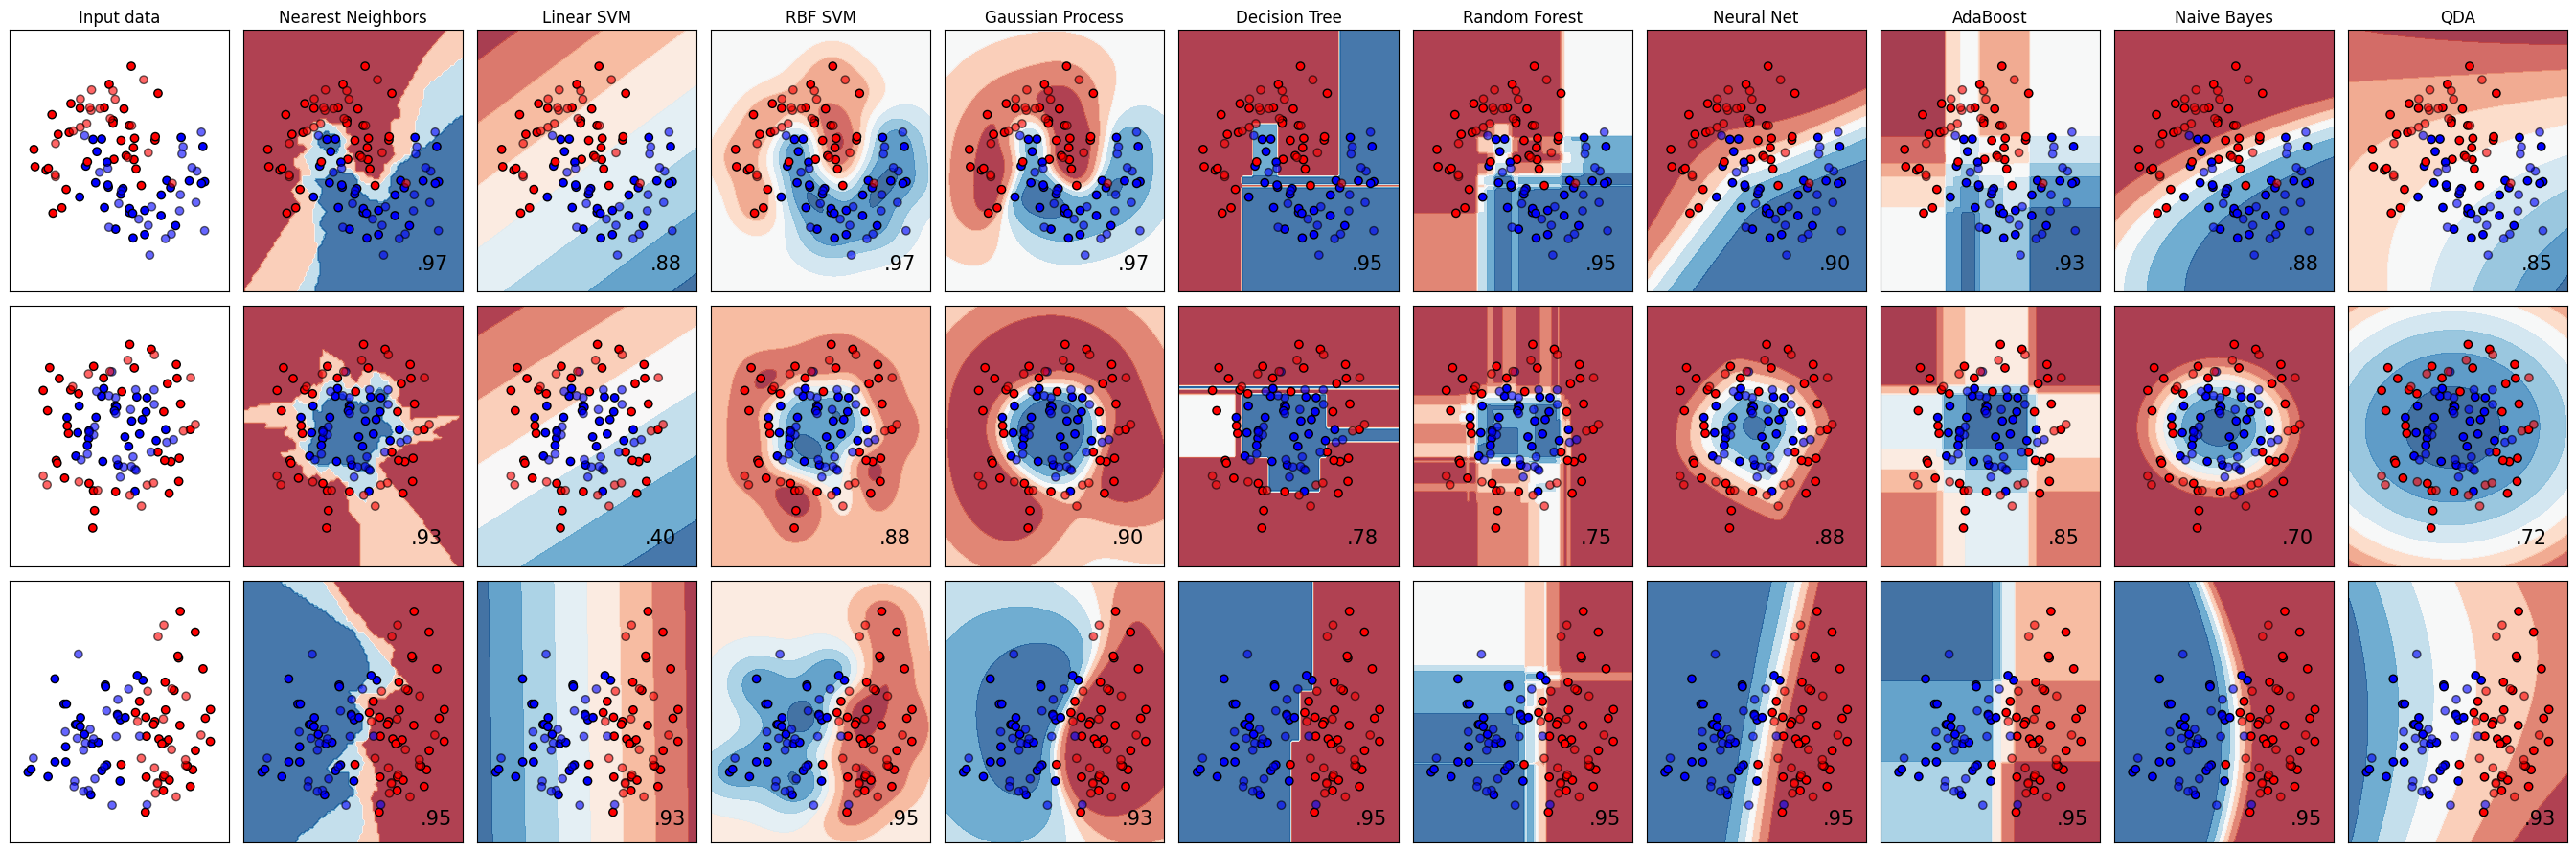

In [ ]:
# Tác giả: Nhóm phát triển scikit-learn
# Giấy phép: BSD-3-Clause

# 1. Khai báo các thư viện hỗ trợ tính toán và hiển thị đồ thị
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

# 2. Import các hàm sinh tập dữ liệu mẫu (synthetic datasets)
from sklearn.datasets import make_circles, make_classification, make_moons

# 3. Import 10 thuật toán phân loại (Classifiers)
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# -------------------------------------------------------------
# CẤU HÌNH DANH SÁCH MÔ HÌNH VÀ THAM SỐ
# -------------------------------------------------------------

# Danh sách tên các mô hình để hiển thị lên tiêu đề cột của đồ thị
names = [
    "Nearest Neighbors",
    "Linear SVM",
    "RBF SVM",
    "Gaussian Process",
    "Decision Tree",
    "Random Forest",
    "Neural Net",
    "AdaBoost",
    "Naive Bayes",
    "QDA",
]

# Khởi tạo các đối tượng phân loại tương ứng với danh sách tên ở trên
classifiers = [
    KNeighborsClassifier(3),  # K-láng giềng gần nhất với k=3
    SVC(kernel="linear", C=0.025, random_state=42),  # SVM với Kernel tuyến tính
    SVC(
        gamma=2, C=1, random_state=42
    ),  # SVM phi tuyến tính dùng RBF (Radial Basis Function)
    GaussianProcessClassifier(
        1.0 * RBF(1.0), random_state=42
    ),  # Quá trình Gauss
    DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),  # Cây quyết định (độ sâu tối đa = 5)
    RandomForestClassifier(
        max_depth=5, n_estimators=10, max_features=1, random_state=42
    ),  # Rừng ngẫu nhiên (10 cây)
    MLPClassifier(
        alpha=1, max_iter=1000, random_state=42
    ),  # Mạng Neural nhiều lớp (Multi-layer Perceptron)
    AdaBoostClassifier(
        random_state=42
    ),  # Thuật toán Boosting tập hợp (AdaBoost)
    GaussianNB(),  # Naive Bayes phân phối chuẩn
    QuadraticDiscriminantAnalysis(),  # Phân tích biệt thức bậc hai (QDA)
]

# -------------------------------------------------------------
# KHỞI TẠO CÁC TẬP DỮ LIỆU MẪU (2 CHIỀU)
# -------------------------------------------------------------

# Tạo tập dữ liệu thứ 3: Tập dữ liệu phân tách tuyến tính (Linearly Separable)
X, y = make_classification(
    n_features=2,  # 2 đặc trưng (tọa độ x, y để vẽ 2D)
    n_redundant=0,
    n_informative=2,
    random_state=1,
    n_clusters_per_class=1,
)
rng = np.random.RandomState(2)
X += 2 * rng.uniform(
    size=X.shape
)  # Thêm nhiễu ngẫu nhiên để dữ liệu không quá tách biệt hoàn hảo
linearly_separable = (X, y)

# Gom 3 tập dữ liệu cần đánh giá vào 1 danh sách
datasets = [
    make_moons(
        noise=0.3, random_state=0
    ),  # Dữ liệu dạng 2 hình bán nguyệt lồng nhau (Moons)
    make_circles(
        noise=0.2, factor=0.5, random_state=1
    ),  # Dữ liệu dạng 2 vòng tròn đồng tâm (Circles)
    linearly_separable,  # Dữ liệu phân tách tuyến tính
]

# -------------------------------------------------------------
# TIẾN HÀNH HUẤN LUYỆN, ĐÁNH GIÁ VÀ VẼ ĐỒ THỊ
# -------------------------------------------------------------

figure = plt.figure(figsize=(27, 9))  # Tạo khung hình kích thước lớn 27x9 inch
i = 1

# Vòng lặp qua từng tập dữ liệu (tương ứng với 3 hàng trên đồ thị)
for ds_cnt, ds in enumerate(datasets):
    # Tách dữ liệu thành ma trận đặc trưng X và nhãn y
    X, y = ds

    # Phân chia dữ liệu: 60% huấn luyện (Train), 40% kiểm thử (Test)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.4, random_state=42
    )

    # Xác định giới hạn trục x, y để căn chỉnh khung hình đồng đều
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    # Cấu hình bảng màu: Đỏ (Class 0) và Xanh dương (Class 1)
    cm = plt.cm.RdBu
    cm_bright = ListedColormap(["#FF0000", "#0000FF"])

    # Cột đầu tiên (Cột 1): Vẽ phân bố của tập dữ liệu gốc (Input Data)
    ax = plt.subplot(len(datasets), len(classifiers) + 1, i)
    if ds_cnt == 0:
        ax.set_title("Input data")

    # Vẽ các điểm thuộc tập Train (màu đậm, viền đen)
    ax.scatter(
        X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright, edgecolors="k"
    )
    # Vẽ các điểm thuộc tập Test (độ trong suốt alpha=0.6)
    ax.scatter(
        X_test[:, 0],
        X_test[:, 1],
        c=y_test,
        cmap=cm_bright,
        alpha=0.6,
        edgecolors="k",
    )

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(())  # Ẩn nhãn trục x
    ax.set_yticks(())  # Ẩn nhãn trục y
    i += 1

    # Vòng lặp chạy qua 10 mô hình phân loại (tương ứng với 10 cột tiếp theo)
    for name, clf in zip(names, classifiers):
        ax = plt.subplot(len(datasets), len(classifiers) + 1, i)

        # Tạo luồng xử lý: Chuẩn hóa dữ liệu (StandardScaler) trước rồi mới đưa vào mô hình (clf)
        clf = make_pipeline(StandardScaler(), clf)

        # Huấn luyện mô hình trên tập Train
        clf.fit(X_train, y_train)

        # Tính toán độ chính xác (Accuracy score) trên tập Test
        score = clf.score(X_test, y_test)

        # Vẽ ranh giới quyết định (Decision Boundary) của mô hình lên nền đồ thị
        DecisionBoundaryDisplay.from_estimator(
            clf, X, cmap=cm, alpha=0.8, ax=ax, eps=0.5
        )

        # Vẽ lại các điểm Train đè lên ranh giới quyết định
        ax.scatter(
            X_train[:, 0],
            X_train[:, 1],
            c=y_train,
            cmap=cm_bright,
            edgecolors="k",
        )
        # Vẽ lại các điểm Test đè lên ranh giới quyết định
        ax.scatter(
            X_test[:, 0],
            X_test[:, 1],
            c=y_test,
            cmap=cm_bright,
            edgecolors="k",
            alpha=0.6,
        )

        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)
        ax.set_xticks(())
        ax.set_yticks(())

        # Đặt tên thuật toán ở hàng đầu tiên
        if ds_cnt == 0:
            ax.set_title(name)

        # Hiển thị điểm số chính xác (Test Accuracy) ở góc dưới cùng bên phải
        ax.text(
            x_max - 0.3,
            y_min + 0.3,
            ("%.2f" % score).lstrip(
                "0"
            ),  # Định dạng số dạng .95 (bỏ số 0 ở đầu)
            size=15,
            horizontalalignment="right",
        )
        i += 1

plt.tight_layout()  # Tự động căn chỉnh lề các đồ thị cho đẹp mắt
plt.show()  # Hiển thị cửa sổ biểu đồ